In [1]:
# Cell 1
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms


SEED = 1

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.14.1+cu130
Device: cuda
GPU: NVIDIA GeForce RTX 4080 Laptop GPU


In [2]:
# Cell 2
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))


Training images: 60000
Test images: 10000


Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Pixel value range: 0.0 to 1.0


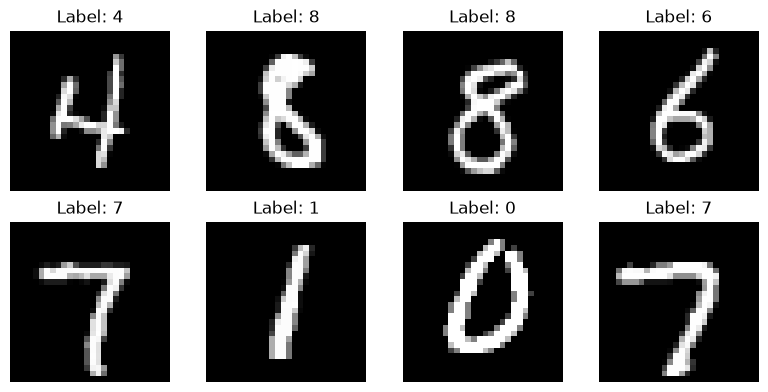

In [3]:

# Cell 3
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel value range:", images.min().item(), "to", images.max().item())

plt.figure(figsize=(8, 4))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i, 0], cmap="gray")
    plt.title(f"Label: {labels[i].item()}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [4]:

# Cell 4
class ContractingResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=2):
        super().__init__()

        #Main Path
        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        if in_channels != out_channels or stride != 1:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity

        out = self.relu(out)

        return out


In [5]:

# Cell 5
class ContractingResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(
                1, 256,
                kernel_size=3,
                stride=1,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.stage1 = ContractingResidualBlock(
            in_channels=256, out_channels=128, stride=2
        )

        self.stage2 = ContractingResidualBlock(
            in_channels=128, out_channels=64, stride=2
        )

        self.stage3 = ContractingResidualBlock(
            in_channels=64, out_channels=32, stride=2
        )

        self.stage4 = ContractingResidualBlock(
            in_channels=32, out_channels=16, stride=2
        )

        self.classifier = nn.Linear(16 * 2 * 2, num_classes)

    def forward(self, x):
        x = self.stem(x)

        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)

        x = torch.flatten(x, start_dim=1)

        x = self.classifier(x)

        return x


In [6]:

# Cell 6
model = ContractingResNet(num_classes=10).to(device)

dummy_input = torch.randn(64, 1, 28, 28, device=device)

with torch.no_grad():
    dummy_output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)

total_params = sum(
    parameter.numel() for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Model device:", next(model.parameters()).device)


Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])
Total parameters: 635,946
Trainable parameters: 635,946
Model device: cuda:0


In [7]:

# Cell 7
model.eval()

with torch.no_grad():
    x = torch.randn(1, 1, 28, 28, device=device)

    print("Input:   ", x.shape)

    x = model.stem(x)
    print("Stem:    ", x.shape)

    x = model.stage1(x)
    print("Stage 1: ", x.shape)

    x = model.stage2(x)
    print("Stage 2: ", x.shape)

    x = model.stage3(x)
    print("Stage 3: ", x.shape)

    x = model.stage4(x)
    print("Stage 4: ", x.shape)

    x = torch.flatten(x, start_dim=1)
    print("Flatten: ", x.shape)

    x = model.classifier(x)
    print("Output:  ", x.shape)


Input:    torch.Size([1, 1, 28, 28])
Stem:     torch.Size([1, 256, 28, 28])
Stage 1:  torch.Size([1, 128, 14, 14])
Stage 2:  torch.Size([1, 64, 7, 7])
Stage 3:  torch.Size([1, 32, 4, 4])
Stage 4:  torch.Size([1, 16, 2, 2])
Flatten:  torch.Size([1, 64])
Output:   torch.Size([1, 10])


In [8]:

# Cell 8
from torch.utils.data import random_split, DataLoader

VALIDATION_SIZE = 5000
TRAIN_SIZE = len(train_dataset) - VALIDATION_SIZE

generator = torch.Generator().manual_seed(SEED)

train_subset, val_subset = random_split(
    train_dataset,
    [TRAIN_SIZE, VALIDATION_SIZE],
    generator=generator
)

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Test images:", len(test_dataset))


Training images: 55000
Validation images: 5000
Test images: 10000


In [17]:

# Cell 9
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 41

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate:", 0.001)
print("Epochs:", EPOCHS)


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Epochs: 41


In [14]:

# Cell 10
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    average_loss = total_loss / total
    accuracy = 100.0 * correct / total

    return average_loss, accuracy


def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += batch_size

    average_loss = total_loss / total
    accuracy = 100.0 * correct / total

    return average_loss, accuracy


In [15]:

# Cell 11
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

start_time = time.time()

for epoch in range(EPOCHS):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

elapsed_time = time.time() - start_time

print(f"\nTraining time: {elapsed_time:.1f} seconds")


Epoch [1/100] | Train Loss: 0.0120 | Train Acc: 99.58% | Val Loss: 0.0270 | Val Acc: 99.06%
Epoch [2/100] | Train Loss: 0.0074 | Train Acc: 99.77% | Val Loss: 0.0404 | Val Acc: 98.80%
Epoch [3/100] | Train Loss: 0.0070 | Train Acc: 99.76% | Val Loss: 0.0271 | Val Acc: 99.18%
Epoch [4/100] | Train Loss: 0.0075 | Train Acc: 99.77% | Val Loss: 0.0220 | Val Acc: 99.28%
Epoch [5/100] | Train Loss: 0.0063 | Train Acc: 99.78% | Val Loss: 0.0309 | Val Acc: 99.06%
Epoch [6/100] | Train Loss: 0.0055 | Train Acc: 99.81% | Val Loss: 0.0345 | Val Acc: 99.08%
Epoch [7/100] | Train Loss: 0.0055 | Train Acc: 99.82% | Val Loss: 0.0248 | Val Acc: 99.24%
Epoch [8/100] | Train Loss: 0.0039 | Train Acc: 99.86% | Val Loss: 0.0260 | Val Acc: 99.24%
Epoch [9/100] | Train Loss: 0.0044 | Train Acc: 99.86% | Val Loss: 0.0233 | Val Acc: 99.34%
Epoch [10/100] | Train Loss: 0.0050 | Train Acc: 99.85% | Val Loss: 0.0302 | Val Acc: 99.20%
Epoch [11/100] | Train Loss: 0.0034 | Train Acc: 99.89% | Val Loss: 0.0225 | Va

KeyboardInterrupt: 

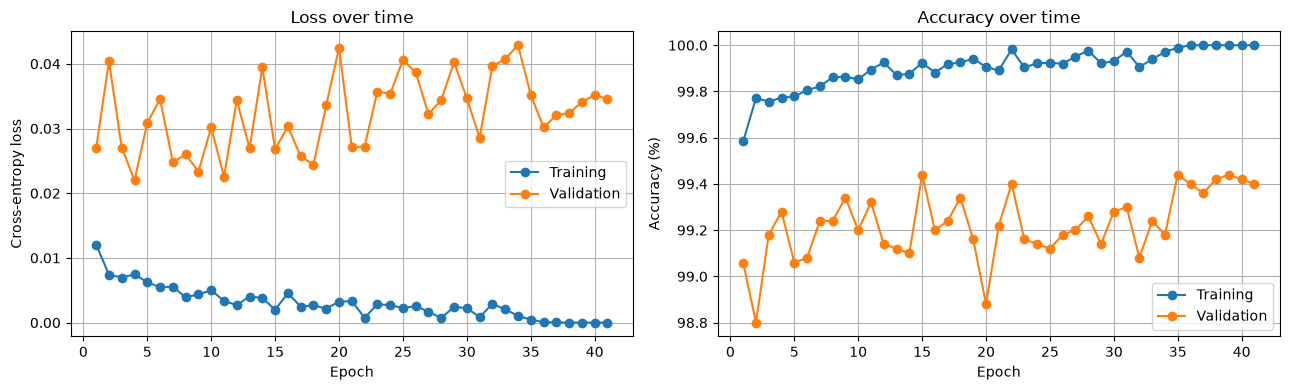

In [18]:

# Cell 12
epochs = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs, history["train_loss"], marker="o", label="Training")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss over time")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Training")
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy over time")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()
